In [17]:
ISM = "Xasanov Temur"
print("Talaba:", ISM)

Talaba: Xasanov Temur


In [18]:
import numpy as np
import pandas as pd
import zlib
np.random.seed(zlib.crc32(ISM.encode()))
N = 500
toifalar = ["Elektronika", "elektronika ", "Kiyim", " kiyim",
"KIYIM", "Kitob", "kitob"]
df = pd.DataFrame({
"buyurtma_id": np.arange(1, N + 1),
"toifa": np.random.choice(toifalar, N),
"narx": np.random.randint(20, 1001, N).astype(str),
"soni": np.random.randint(1, 6, N).astype(float),
"baho": np.random.randint(1, 6, N).astype(float),
})
df.loc[np.random.rand(N) < 0.02, "toifa"] = np.nan
df.loc[np.random.rand(N) < 0.03, "narx"] = "noma'lum"
df.loc[np.random.rand(N) < 0.02, "narx"] = "-100"
df.loc[np.random.rand(N) < 0.05, "soni"] = np.nan
df.loc[np.random.rand(N) < 0.03, "baho"] = 9
k = np.random.randint(5, 16)
df = pd.concat([df, df.sample(k)], ignore_index=True)

In [19]:
df.shape
df.head()
df.info()
df.isna().sum()
df.duplicated().sum()
df["toifa"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 513 entries, 0 to 512
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   buyurtma_id  513 non-null    int64  
 1   toifa        497 non-null    str    
 2   narx         513 non-null    str    
 3   soni         493 non-null    float64
 4   baho         513 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 20.2 KB


toifa
Kiyim           80
Kitob           78
Elektronika     75
kitob           71
elektronika     67
KIYIM           65
 kiyim          61
Name: count, dtype: int64

In [20]:
old_shape = df.shape
print("Oldingi shape:", old_shape)
print("Oldingi bo'sh qiymatlar:", df.isna().sum().sum())

Oldingi shape: (513, 5)
Oldingi bo'sh qiymatlar: 36


In [21]:
df["toifa"] = df["toifa"].str.strip().str.title()

df["narx"] = pd.to_numeric(df["narx"], errors="coerce")

df.loc[df["narx"] <= 0, "narx"] = None
df.loc[df["baho"] > 5, "baho"] = None

df = df.drop_duplicates()
df = df.dropna(subset=["soni"])

df["narx"] = df["narx"].fillna(df["narx"].median())
df["baho"] = df["baho"].fillna(df["baho"].median())
df["toifa"] = df["toifa"].fillna("Noma'lum")

In [22]:
print("Oldingi shape:", old_shape)
print("Keyingi shape:", df.shape)
print("Bo'sh qiymatlar:", df.isna().sum().sum())

Oldingi shape: (513, 5)
Keyingi shape: (481, 5)
Bo'sh qiymatlar: 0


In [23]:
df["summa"] = df["narx"] * df["soni"]

df.groupby("toifa")["summa"].sum()

toifa
Elektronika    203721.0
Kitob          212139.0
Kiyim          271785.0
Noma'lum        22690.0
Name: summa, dtype: float64

In [24]:
import kagglehub
import pandas as pd
import numpy as np

path = kagglehub.dataset_download(
    "carrie1/ecommerce-data",
    path="data.csv"
)

df = pd.read_csv(path, encoding="ISO-8859-1")

print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [25]:
df.info()
df.isna().sum()
df.duplicated().sum()
print("Quantity < 0:", (df["Quantity"] < 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("Bekor qilingan buyurtmalar:", df["InvoiceNo"].astype(str).str.startswith("C").sum())


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
Quantity < 0: 10624
UnitPrice <= 0: 2517
Bekor qilingan buyurtmalar: 9288


In [26]:
old_shape = df.shape
print("Oldingi shape:", old_shape)

Oldingi shape: (541909, 8)


df = df.drop_duplicates()
df = df.dropna(subset=["CustomerID"])
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]
df["CustomerID"] = df["CustomerID"].astype(int)
df["Description"] = df["Description"].fillna("Noma'lum").str.strip()
df["summa"] = df["Quantity"] * df["UnitPrice"]

In [27]:
print("Oldingi shape:", old_shape)
print("Keyingi shape:", df.shape)
foiz = len(df) / old_shape[0] * 100
print("Qolgan qatorlar foizi:", round(foiz, 2), "%")
print("Bo'sh qiymatlar:", df.isna().sum().sum())

Oldingi shape: (541909, 8)
Keyingi shape: (541909, 8)
Qolgan qatorlar foizi: 100.0 %
Bo'sh qiymatlar: 136534


In [28]:
df.to_csv("retail_toza.csv", index=False)
print("Fayl muvaffaqiyatli saqlandi!")

Fayl muvaffaqiyatli saqlandi!


In [29]:
df["summa"] = df["Quantity"] * df["UnitPrice"]
country_sales = df.groupby("Country")["summa"].sum()
top_5 = country_sales.sort_values(ascending=False).head(5)
print(top_5)

Country
United Kingdom    8187806.364
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Name: summa, dtype: float64


In [30]:
total_sales = df["summa"].sum()
uk_sales = country_sales["United Kingdom"]
uk_percentage = (uk_sales / total_sales) * 100
print("Umumiy daromad:", round(total_sales, 2))
print("UK daromadi:", round(uk_sales, 2))
print("UK ulushi:", round(uk_percentage, 2), "%")

Umumiy daromad: 9747747.93
UK daromadi: 8187806.36
UK ulushi: 84.0 %


In [31]:
df["uk"] = df["Country"] == "United Kingdom"

In [32]:
average_sales = df.groupby("uk")["summa"].mean()
print(average_sales)

uk
False    33.596984
True     16.525065
Name: summa, dtype: float64


In [33]:
print(df["uk"].value_counts())

uk
True     495478
False     46431
Name: count, dtype: int64


In [34]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["oy"] = df["InvoiceDate"].dt.month
monthly_sales = df.groupby("oy")["summa"].sum()
print(monthly_sales.sort_values(ascending=False))
year_end_sales = monthly_sales[monthly_sales.index.isin([10, 11, 12])].sum()
other_sales = monthly_sales[~monthly_sales.index.isin([10, 11, 12])].sum()
print("Yil oxiri daromadi:", round(year_end_sales, 2))
print("Boshqa oylar daromadi:", round(other_sales, 2))

oy
11    1461756.250
12    1182625.030
10    1070704.670
9     1019687.622
5      723333.510
6      691123.120
3      683267.080
8      682680.510
7      681300.111
1      560000.260
2      498062.650
4      493207.121
Name: summa, dtype: float64
Yil oxiri daromadi: 3715085.95
Boshqa oylar daromadi: 6032661.98


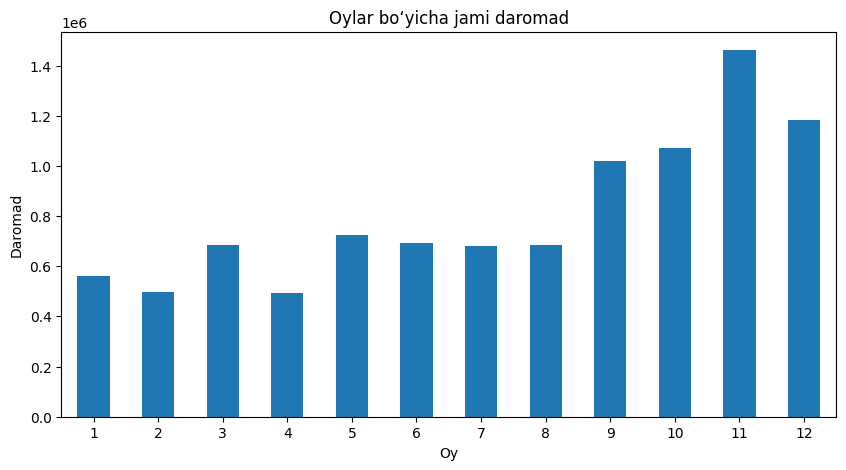

In [35]:
import matplotlib.pyplot as plt
monthly_sales.sort_index().plot(kind="bar", figsize=(10, 5))
plt.title("Oylar bo‘yicha jami daromad")
plt.xlabel("Oy")
plt.ylabel("Daromad")
plt.xticks(rotation=0)
plt.show()

In [36]:
h1 = uk_percentage > 50
h2 = average_sales[False] > average_sales[True]
h3 = year_end_sales > other_sales
report = pd.DataFrame({
    "Gipoteza": [
        "UK daromadning 50% dan ko‘pini beradi",
        "Chet ellik mijozlarning xaridi kattaroq",
        "Yil oxiridagi daromad yuqoriroq"
    ],
    "Natija": [
        f"{uk_percentage:.2f}%",
        f"Chet el: {average_sales[False]:.2f}, UK: {average_sales[True]:.2f}",
        f"Yil oxiri: {year_end_sales:.2f}, boshqa oylar: {other_sales:.2f}"
    ],
    "Qaror": [
        "Tasdiqlandi" if h1 else "Rad etildi",
        "Tasdiqlandi" if h2 else "Rad etildi",
        "Tasdiqlandi" if h3 else "Rad etildi"
    ]
})
report

,Gipoteza,Natija,Qaror
0,UK daromadning 50% dan ko‘pini beradi,84.00%,Tasdiqlandi
1,Chet ellik mijozlarning xaridi kattaroq,"Chet el: 33.60, UK: 16.53",Tasdiqlandi
2,Yil oxiridagi daromad yuqoriroq,"Yil oxiri: 3715085.95, boshqa oylar: 6032661.98",Rad etildi


In [37]:
if h1:
    print(f"UK bozoriga e'tibor berish kerak. Daromadning {uk_percentage:.2f}% shu mamlakat hissasiga to'g'ri keladi.")
else:
    print(f"UK daromadi {uk_percentage:.2f}%. Boshqa mamlakatlar bozorini ham rivojlantirish kerak.")

if h2:
    print("Chet ellik mijozlar uchun yuqoriroq qiymatli mahsulotlar va marketing takliflarini ishlab chiqish kerak.")
else:
    print("UK mijozlarining o'rtacha xaridi yuqoriroq. UK mijozlarini saqlab qolishga e'tibor berish kerak.")

if h3:
    print("Oktyabr-dekabr oylariga mahsulot zaxirasi va marketing byudjetini oshirish kerak.")
else:
    print("Yil oxiri daromadi boshqa oylardan yuqori emas. Daromadi yuqori oylarni alohida o'rganish kerak.")

UK bozoriga e'tibor berish kerak. Daromadning 84.00% shu mamlakat hissasiga to'g'ri keladi.
Chet ellik mijozlar uchun yuqoriroq qiymatli mahsulotlar va marketing takliflarini ishlab chiqish kerak.
Yil oxiri daromadi boshqa oylardan yuqori emas. Daromadi yuqori oylarni alohida o'rganish kerak.
